# BTC/USDT 30-min — Mean-Reversion Strategy (z-score)

Rule-based benchmark to compare against the LightGBM / LSTM models in this folder.

**Concept**: price tends to revert to a rolling average after a short-term deviation.

$$z_t = \frac{P_t - \mu_t}{\sigma_t}, \qquad \mu_t,\ \sigma_t = \text{rolling mean / std of the last } W \text{ closes}$$

Example from the brief: 20-period mean = 80, σ = 2, price = 84 → z = (84 − 80)/2 = 2.0.
**z > +entry → short**, **z < −entry → long**.

Variants tested

| name | rule |
|---|---|
| `slide rule` | literal rule: W = 20 bars, short while z > 2, long while z < −2, flat otherwise |
| `hold to mean` | enter at ±entry_z, **hold until z reverts** to ±exit_z (the usual way it is traded) |
| `intraday mean` | the "high-frequency twist": μ, σ from bars of the **same UTC day** only |
| `long-only` | same rules but **never short**: buy when z < −entry, sell back to cash on exit (what Binance spot allows without margin) |

**No look-ahead**: z uses the close of bar *t*; the order is filled at the **open of bar t+1**
(the trade-tracker convention: position at index t is executed at bar t's open).
Backtest, costs and metrics come from `AlgoGoneCrazy-dev-trade-tracker/src` so the numbers are
directly comparable with the ML strategies. Parameters are chosen on **validation**, reported on **test**.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)


def find_repo_root(start: Path = Path.cwd()) -> Path:
    """Walk up from the notebook folder until the folder holding all AlgoGoneCrazy-dev-* repos."""
    for p in [start, *start.parents]:
        if (p / "AlgoGoneCrazy-dev-trade-tracker").is_dir():
            return p
    raise FileNotFoundError("Could not find AlgoGoneCrazy-dev-trade-tracker above " + str(start))


REPO_ROOT = find_repo_root()
TRACKER_DIR = REPO_ROOT / "AlgoGoneCrazy-dev-trade-tracker"   # backtest engine + metrics
MODEL_DIR = REPO_ROOT / "AlgoGoneCrazy-dev-model" / "model"
RESULTS_DIR = MODEL_DIR / "results"
RESULTS_DIR.mkdir(exist_ok=True)

# import the shared backtest / metrics code from the trade-tracker repo
if str(TRACKER_DIR) not in sys.path:
    sys.path.insert(0, str(TRACKER_DIR))
from src.backtest import run_backtest, buy_and_hold
from src.strategy import hold_signals
from src.metrics import compute_metrics, drawdown_series

print("repo root   :", REPO_ROOT)
print("backtest src:", TRACKER_DIR / "src")

repo root   : C:/Users/user/projects/Githubrepo
backtest src: C:/Users/user/projects/Githubrepo/AlgoGoneCrazy-dev-trade-tracker/src


## 1. Settings

In [2]:
# --- transaction costs (BTC on Binance, see AlgoGoneCrazy-dev-data/config/cost_assumptions.json)
FEE_BPS = 10.0          # 0.10% standard spot fee per order, no BNB discount
SLIPPAGE_BPS = 2.0      # half-spread + impact per order (same as trade-tracker config.py)
INITIAL_CASH = 100_000.0
ALLOW_SHORT = True

# --- chronological split, same fractions as the ML notebooks (70 / 15 / 15)
TRAIN_FRAC, VAL_FRAC = 0.70, 0.15

BT_KW = dict(initial_cash=INITIAL_CASH, fee_bps=FEE_BPS, slippage_bps=SLIPPAGE_BPS)

# --- slide-rule parameters
SLIDE_WINDOW = 20       # "20-day moving average" -> 20 bars here (10 hours of 30-min bars)
SLIDE_ENTRY_Z = 2.0

# --- search grid for the hold-to-mean variant (chosen on VALIDATION Sharpe)
GRID_WINDOW = [20, 48, 96, 192]      # 10h, 1d, 2d, 4d
GRID_ENTRY_Z = [1.5, 2.0, 2.5, 3.0]
GRID_EXIT_Z = [0.0, 0.5]
MAX_HOLD = None         # optional time stop in bars (e.g. 48); None = hold until reversion
SIDES = {"long/short": True, "long-only": False}   # grid is searched for both

TAG = "btc_mean_reversion"

## 2. Load 30-min BTC bars

In [3]:
# First file found is used: DATA_PATH if set, then the newest BTCUSDT snapshot in the team's
# "Tsai Yi Kai - FE5209_Group_Project" OneDrive folder, then model/data/ (where the ML notebooks
# read from), then the dev-data canonical multi-asset file (filtered to BTC).
DATA_PATH = None   # set a full path here to override the search below


def shared_drive_btc_files():
    """Team OneDrive folder: .../FE5209_Group_Project/data/<yymmdd>/staging/binance_spot/BTCUSDT/.
    Newest dated snapshot first."""
    hits = []
    for base in (Path.home() / "National University of Singapore", REPO_ROOT.parent, REPO_ROOT):
        if base.is_dir():
            hits += base.glob("*FE5209_Group_Project/data/*/staging/binance_spot/BTCUSDT/"
                              "market_bars_30m_with_backfill.csv")
    return sorted(set(hits), key=lambda p: p.parts[-5], reverse=True)


DATA_CANDIDATES = ([Path(DATA_PATH)] if DATA_PATH else []) + shared_drive_btc_files() + [
    MODEL_DIR / "data" / "market_bars_30m_with_backfill.csv",
    REPO_ROOT / "AlgoGoneCrazy-dev-model" / "data" / "market_bars_30m_with_backfill.csv",
    TRACKER_DIR / "data" / "market_bars_30m_with_backfill.csv",
    REPO_ROOT / "AlgoGoneCrazy-dev-data" / "data" / "canonical" / "market_bars_30m.csv",
]
SYMBOL = "BTCUSDT"


def load_btc_bars(candidates=DATA_CANDIDATES, symbol=SYMBOL) -> pd.DataFrame:
    path = next((p for p in candidates if p.exists()), None)
    if path is None:
        raise FileNotFoundError("No 30-min bar CSV found. Put it in one of:\n" +
                                "\n".join(str(p) for p in candidates))
    raw = pd.read_csv(path)
    raw.columns = [c.lower() for c in raw.columns]
    for col in ("source_symbol", "instrument_id", "symbol"):       # multi-asset file -> BTC only
        if col in raw.columns and raw[col].nunique() > 1:
            raw = raw[raw[col].astype(str).str.upper().str.contains("BTC")]
            break
    # UTC, stored tz-naive: trade-tracker's drawdown_episodes() fails on tz-aware
    # timestamps when the last drawdown is still open (NaT + tz-aware -> object dtype)
    raw.index = pd.DatetimeIndex(pd.to_datetime(raw.pop("bar_open_time_utc"), utc=True)).tz_convert(None)
    raw = raw.sort_index()
    raw = raw[~raw.index.duplicated(keep="last")]
    print("loaded:", path)
    return raw[["open", "high", "low", "close", "volume"]].astype(float)


bars = load_btc_bars()
print(bars.shape, bars.index.min(), "->", bars.index.max())
bars.tail()

loaded: C:/Users/user/National University of Singapore/Tsai Yi Kai - FE5209_Group_Project/data/260918/staging/binance_spot/BTCUSDT/market_bars_30m_with_backfill.csv
(52608, 5) 2023-09-17 00:00:00 -> 2026-09-16 23:30:00


,open,high,low,close,volume
bar_open_time_utc,,,,,
2026-09-16 21:30:00,76074.56,76099.98,75933.11,75976.00,126.43911
2026-09-16 22:00:00,75976.01,75986.01,75667.24,75758.21,306.49196
2026-09-16 22:30:00,75758.21,75820.01,75632.70,75675.88,219.03523
2026-09-16 23:00:00,75675.88,76140.62,75643.61,76076.49,236.74200
2026-09-16 23:30:00,76076.49,76276.02,76063.77,76206.01,247.73664


In [4]:
n = len(bars)
train_end, val_end = int(n * TRAIN_FRAC), int(n * (TRAIN_FRAC + VAL_FRAC))
periods = {
    "train": (bars.index[0], bars.index[train_end - 1]),
    "val": (bars.index[train_end], bars.index[val_end - 1]),
    "test": (bars.index[val_end], bars.index[-1]),
}
for k, (a, b) in periods.items():
    print(f"{k:5s}: {a} -> {b}")


def sl(obj, period):
    """Slice a Series/DataFrame to one period (indicators are computed on the full history
    first, so each period starts with warmed-up signals and no look-ahead)."""
    a, b = periods[period]
    return obj.loc[a:b]

train: 2023-09-17 00:00:00 -> 2025-10-23 04:00:00
val  : 2025-10-23 04:30:00 -> 2026-04-05 13:30:00
test : 2026-04-05 14:00:00 -> 2026-09-16 23:30:00


## 3. Z-score and position rules

In [5]:
def zscore(close: pd.Series, window: int) -> pd.Series:
    mu = close.rolling(window).mean()
    sd = close.rolling(window).std()
    return (close - mu) / sd


def intraday_zscore(close: pd.Series, min_bars: int = 6) -> pd.Series:
    """High-frequency twist: mean / std of the bars so far in the same UTC day."""
    day = close.index.floor("D")
    g = close.groupby(day)
    mu = g.transform(lambda s: s.expanding(min_bars).mean())
    sd = g.transform(lambda s: s.expanding(min_bars).std())
    return (close - mu) / sd


def slide_rule_positions(z: pd.Series, entry_z: float = 2.0, allow_short: bool = ALLOW_SHORT) -> pd.Series:
    """Literal rule: short while z > entry, long while z < -entry, flat otherwise."""
    pos = pd.Series(0, index=z.index, dtype=int)
    pos[z < -entry_z] = 1
    if allow_short:
        pos[z > entry_z] = -1
    return pos


def hold_to_mean_positions(z: pd.Series, entry_z: float = 2.0, exit_z: float = 0.0,
                           max_hold=None, allow_short: bool = ALLOW_SHORT) -> pd.Series:
    """Enter at |z| > entry_z, exit when z comes back to +-exit_z (or after max_hold bars).
    An extreme on the other side flips the position."""
    out = np.zeros(len(z), dtype=int)
    pos, held = 0, 0
    for i, zi in enumerate(z.to_numpy()):
        if not np.isnan(zi):
            if pos == 1 and (zi >= -exit_z or (max_hold and held >= max_hold)):
                pos = 0
            elif pos == -1 and (zi <= exit_z or (max_hold and held >= max_hold)):
                pos = 0
            if zi < -entry_z and pos != 1:
                pos, held = 1, 0
            elif allow_short and zi > entry_z and pos != -1:
                pos, held = -1, 0
        out[i] = pos
        held = held + 1 if pos != 0 else 0
    return pd.Series(out, index=z.index, name="position")


def to_executable(signal_pos: pd.Series) -> pd.Series:
    """Decision made at the close of bar t -> held from the open of bar t+1."""
    return signal_pos.shift(1).fillna(0).astype(int)


close = bars["close"]
z20 = zscore(close, SLIDE_WINDOW)
z20.describe()

count    52589.000000
mean         0.048578
std          1.297954
min         -4.020597
25%         -0.940178
50%          0.088653
75%          1.036600
max          4.132919
Name: close, dtype: float64

share of bars with |z| > 2 (W=20): 0.1136


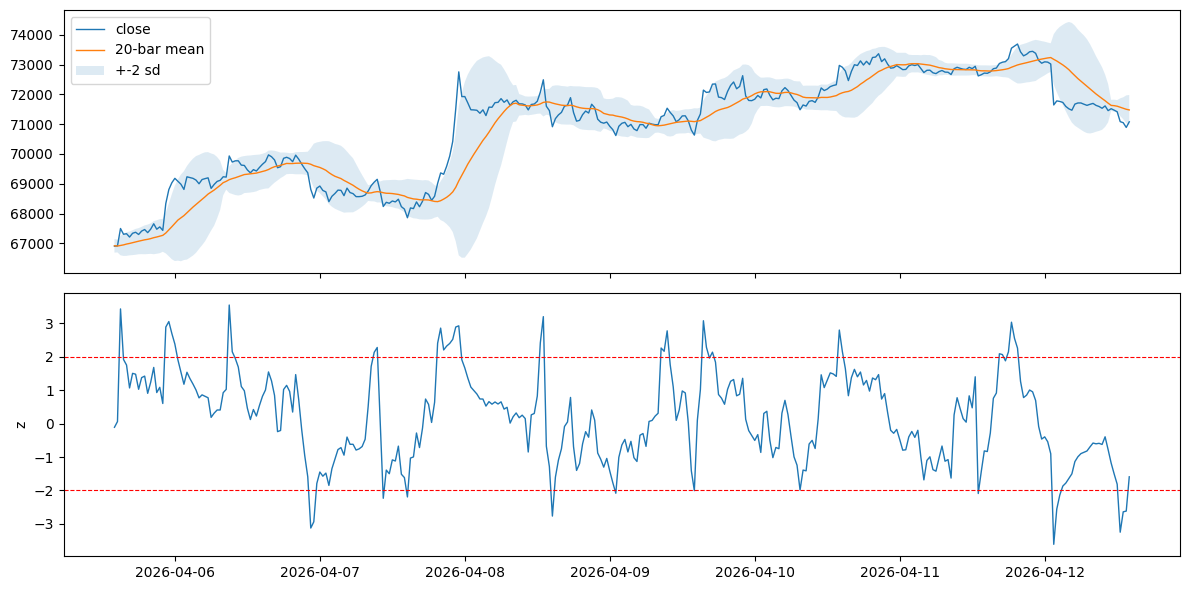

In [6]:
# sanity check with the worked example from the brief: mu = 80, sigma = 2, price = 84 -> z = 2 -> short
assert (84 - 80) / 2 == 2.0
print("share of bars with |z| > 2 (W=20):", round((z20.abs() > 2).mean(), 4))

# one week of price, rolling bands and slide-rule entries
wk = slice(bars.index[val_end], bars.index[val_end] + pd.Timedelta(days=7))
mu = close.rolling(SLIDE_WINDOW).mean()
sd = close.rolling(SLIDE_WINDOW).std()
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].plot(close[wk], lw=1, label="close")
ax[0].plot(mu[wk], lw=1, label=f"{SLIDE_WINDOW}-bar mean")
ax[0].fill_between(mu[wk].index, (mu - 2 * sd)[wk], (mu + 2 * sd)[wk], alpha=0.15, label="+-2 sd")
ax[0].legend()
ax[1].plot(z20[wk], lw=1)
for lvl in (2, -2):
    ax[1].axhline(lvl, ls="--", color="r", lw=0.8)
ax[1].set_ylabel("z")
plt.tight_layout()
plt.show()

## 4. Backtest helpers (shared trade-tracker engine)

In [7]:
def backtest(pos: pd.Series, period: str):
    """Run the shared trade-tracker engine on one period (starts flat, closes out at the end)."""
    return run_backtest(sl(pos, period), sl(bars, period), asset="BTC", **BT_KW)


def metrics(res) -> pd.Series:
    return compute_metrics(res.equity, res.trades, res.positions, res.fills)


# the rows people actually look at first
KEY_ROWS = ["Total Return", "Annual Return", "Annual Volatility", "Sharpe Ratio", "Sortino Ratio",
            "Max Drawdown", "Calmar Ratio", "Number of Trades", "Win Rate",
            "Average Holding Period (hours)", "Profit Factor", "Exposure (time in market)",
            "Annual Return (before costs)", "Annual Cost Drag", "Total Transaction Cost"]

## 5. Parameter search on the validation period

Each (window, entry_z, exit_z) combination is backtested on **train** and **validation**
with full costs. The best validation Sharpe is kept; train Sharpe is shown to check the
choice is not a one-period fluke.

In [8]:
z_cache = {w: zscore(close, w) for w in GRID_WINDOW}
rows = []
for side, short_ok in SIDES.items():
  for w in GRID_WINDOW:
    for ez in GRID_ENTRY_Z:
        for xz in GRID_EXIT_Z:
            pos = to_executable(hold_to_mean_positions(z_cache[w], ez, xz, MAX_HOLD, allow_short=short_ok))
            row = {"side": side, "window": w, "entry_z": ez, "exit_z": xz}
            for p in ("train", "val"):
                m = metrics(backtest(pos, p))
                row[f"{p}_sharpe"] = m["Sharpe Ratio"]
                row[f"{p}_ann_ret"] = m["Annual Return"]
                row[f"{p}_mdd"] = m["Max Drawdown"]
                row[f"{p}_trades"] = m["Number of Trades"]
            rows.append(row)
grid = pd.DataFrame(rows).sort_values("val_sharpe", ascending=False).reset_index(drop=True)
grid.head(10).round(3)

,side,window,entry_z,exit_z,train_sharpe,train_ann_ret,train_mdd,train_trades,val_sharpe,val_ann_ret,val_mdd,val_trades
0,long/short,192,1.5,0.5,-1.494,-0.501,-0.789,321.0,-0.058,-0.101,-0.347,67.0
1,long/short,192,3.0,0.5,-1.124,-0.340,-0.629,114.0,-0.422,-0.166,-0.283,25.0
2,long/short,192,1.5,0.0,-0.951,-0.411,-0.717,260.0,-0.459,-0.262,-0.378,51.0
3,long/short,192,2.0,0.5,-1.385,-0.455,-0.748,230.0,-0.474,-0.217,-0.320,44.0
4,long/short,192,3.0,0.0,-0.608,-0.249,-0.600,108.0,-0.809,-0.291,-0.341,22.0
5,long/short,192,2.5,0.5,-1.447,-0.442,-0.728,165.0,-0.867,-0.300,-0.367,31.0
6,long/short,96,2.5,0.0,-1.511,-0.485,-0.764,305.0,-0.983,-0.366,-0.332,61.0
7,long-only,192,2.0,0.5,0.004,-0.033,-0.257,107.0,-0.993,-0.312,-0.315,23.0
8,long-only,192,3.0,0.5,0.490,0.087,-0.152,55.0,-1.002,-0.273,-0.282,13.0
9,long-only,192,1.5,0.5,-0.048,-0.051,-0.272,153.0,-1.073,-0.349,-0.351,33.0


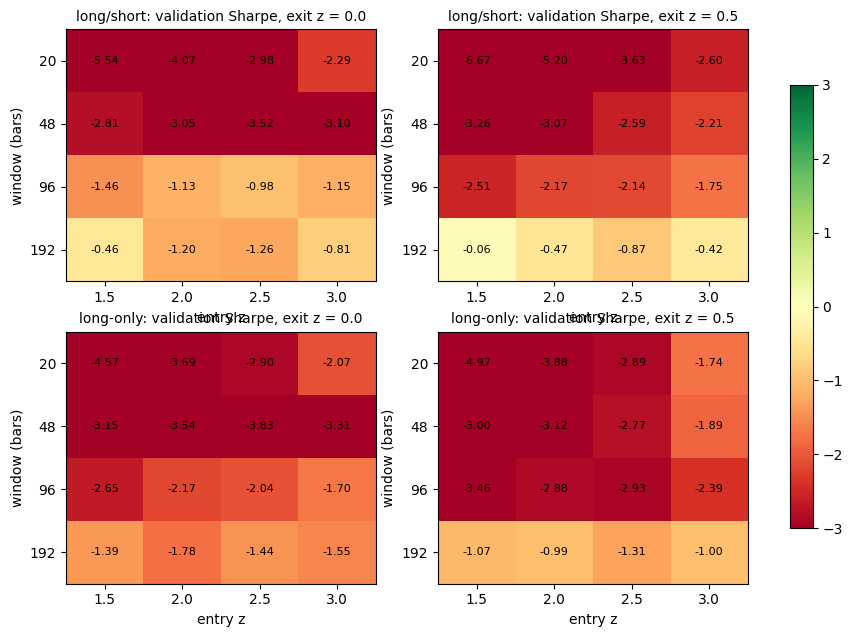

long/short chosen on validation: window=192, entry_z=1.5, exit_z=0.5
long-only  chosen on validation: window=192, entry_z=2.0, exit_z=0.5


In [9]:
fig, axes = plt.subplots(len(SIDES), len(GRID_EXIT_Z), figsize=(5.5 * len(GRID_EXIT_Z), 3.6 * len(SIDES)),
                         squeeze=False)
for ax, (side, xz) in zip(axes.ravel(), [(sd_, xz_) for sd_ in SIDES for xz_ in GRID_EXIT_Z]):
    hm = grid[(grid.side == side) & (grid.exit_z == xz)].pivot(index="window", columns="entry_z",
                                                                 values="val_sharpe")
    im = ax.imshow(hm.values, cmap="RdYlGn", vmin=-3, vmax=3, aspect="auto")
    ax.set_xticks(range(hm.shape[1]), hm.columns)
    ax.set_yticks(range(hm.shape[0]), hm.index)
    for i in range(hm.shape[0]):
        for j in range(hm.shape[1]):
            ax.text(j, i, f"{hm.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
    ax.set_xlabel("entry z")
    ax.set_ylabel("window (bars)")
    ax.set_title(f"{side}: validation Sharpe, exit z = {xz}", fontsize=10)
fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.8)
plt.show()

best = grid[grid.side == "long/short"].iloc[0]
BEST_W, BEST_EZ, BEST_XZ = int(best.window), float(best.entry_z), float(best.exit_z)
best_lo = grid[grid.side == "long-only"].iloc[0]
LO_W, LO_EZ, LO_XZ = int(best_lo.window), float(best_lo.entry_z), float(best_lo.exit_z)
print(f"long/short chosen on validation: window={BEST_W}, entry_z={BEST_EZ}, exit_z={BEST_XZ}")
print(f"long-only  chosen on validation: window={LO_W}, entry_z={LO_EZ}, exit_z={LO_XZ}")

## 6. Final positions for every variant

In [10]:
BEST_NAME = f"hold to mean (W={BEST_W}, z={BEST_EZ}/{BEST_XZ})"
strategies = {
    f"slide rule (W={SLIDE_WINDOW}, z={SLIDE_ENTRY_Z})":
        to_executable(slide_rule_positions(z20, SLIDE_ENTRY_Z)),
    f"hold to mean (W={SLIDE_WINDOW}, z={SLIDE_ENTRY_Z}/0)":
        to_executable(hold_to_mean_positions(z20, SLIDE_ENTRY_Z, 0.0, MAX_HOLD)),
    BEST_NAME:
        to_executable(hold_to_mean_positions(zscore(close, BEST_W), BEST_EZ, BEST_XZ, MAX_HOLD)),
    f"intraday mean (z={SLIDE_ENTRY_Z}/0)":
        to_executable(hold_to_mean_positions(intraday_zscore(close), SLIDE_ENTRY_Z, 0.0, MAX_HOLD)),
    # long-only: buy the dip, sell back to cash - never short
    f"LONG-ONLY slide rule (W={SLIDE_WINDOW}, z={SLIDE_ENTRY_Z})":
        to_executable(slide_rule_positions(z20, SLIDE_ENTRY_Z, allow_short=False)),
    f"LONG-ONLY hold to mean (W={SLIDE_WINDOW}, z={SLIDE_ENTRY_Z}/0)":
        to_executable(hold_to_mean_positions(z20, SLIDE_ENTRY_Z, 0.0, MAX_HOLD, allow_short=False)),
    f"LONG-ONLY best (W={LO_W}, z={LO_EZ}/{LO_XZ})":
        to_executable(hold_to_mean_positions(zscore(close, LO_W), LO_EZ, LO_XZ, MAX_HOLD, allow_short=False)),
}
pd.DataFrame({k: v.value_counts(normalize=True) for k, v in strategies.items()}).round(3)

,"slide rule (W=20, z=2.0)","hold to mean (W=20, z=2.0/0)","hold to mean (W=192, z=1.5/0.5)",intraday mean (z=2.0/0),"LONG-ONLY slide rule (W=20, z=2.0)","LONG-ONLY hold to mean (W=20, z=2.0/0)","LONG-ONLY best (W=192, z=2.0/0.5)"
-1,0.057,0.267,0.315,0.261,NaN,NaN,NaN
0,0.886,0.481,0.416,0.495,0.944,0.748,0.775
1,0.056,0.252,0.269,0.244,0.056,0.252,0.225


## 7. Performance matrix — test period (out of sample)

In [11]:
test_results = {name: backtest(pos, "test") for name, pos in strategies.items()}
test_results["Buy & Hold"] = buy_and_hold(sl(bars, "test"), asset="BTC", **BT_KW)

table = pd.DataFrame({name: metrics(res) for name, res in test_results.items()})
table.loc[KEY_ROWS].style.format("{:,.4f}")

,"slide rule (W=20, z=2.0)","hold to mean (W=20, z=2.0/0)","hold to mean (W=192, z=1.5/0.5)",intraday mean (z=2.0/0),"LONG-ONLY slide rule (W=20, z=2.0)","LONG-ONLY hold to mean (W=20, z=2.0/0)","LONG-ONLY best (W=192, z=2.0/0.5)",Buy & Hold
Total Return,-0.6867,-0.3796,-0.2817,-0.3773,-0.3848,-0.0607,-0.1316,0.1378
Annual Return,-0.9240,-0.6535,-0.5204,-0.6507,-0.6600,-0.1298,-0.2690,0.3318
Annual Volatility,0.1889,0.3074,0.3400,0.2981,0.1188,0.2067,0.2212,0.3887
Sharpe Ratio,-13.5461,-3.2933,-1.9904,-3.3792,-9.0171,-0.5696,-1.3052,0.9317
Sortino Ratio,-16.1589,-4.5012,-2.6536,-4.5082,-11.4574,-0.8300,-1.7441,1.3367
Max Drawdown,-0.6896,-0.3948,-0.3598,-0.3957,-0.3941,-0.2169,-0.2346,-0.2953
Calmar Ratio,-1.3400,-1.6551,-1.4462,-1.6443,-1.6747,-0.5984,-1.1465,1.1237
Number of Trades,449.0000,299.0000,68.0000,227.0000,229.0000,148.0000,22.0000,1.0000
Win Rate,0.2339,0.5351,0.6471,0.5463,0.2445,0.5878,0.7273,1.0000
Average Holding Period (hours),1.0067,6.8896,35.2279,9.2159,0.9345,6.7703,46.2273,"3,945.5000"


In [12]:
# full matrix, all metrics from src/metrics.py (incl. transaction-cost section)
table.style.format("{:,.4f}")

,"slide rule (W=20, z=2.0)","hold to mean (W=20, z=2.0/0)","hold to mean (W=192, z=1.5/0.5)",intraday mean (z=2.0/0),"LONG-ONLY slide rule (W=20, z=2.0)","LONG-ONLY hold to mean (W=20, z=2.0/0)","LONG-ONLY best (W=192, z=2.0/0.5)",Buy & Hold
Total Return,-0.6867,-0.3796,-0.2817,-0.3773,-0.3848,-0.0607,-0.1316,0.1378
Annual Return,-0.9240,-0.6535,-0.5204,-0.6507,-0.6600,-0.1298,-0.2690,0.3318
Annual Volatility,0.1889,0.3074,0.3400,0.2981,0.1188,0.2067,0.2212,0.3887
Sharpe Ratio,-13.5461,-3.2933,-1.9904,-3.3792,-9.0171,-0.5696,-1.3052,0.9317
Sortino Ratio,-16.1589,-4.5012,-2.6536,-4.5082,-11.4574,-0.8300,-1.7441,1.3367
Max Drawdown,-0.6896,-0.3948,-0.3598,-0.3957,-0.3941,-0.2169,-0.2346,-0.2953
Calmar Ratio,-1.3400,-1.6551,-1.4462,-1.6443,-1.6747,-0.5984,-1.1465,1.1237
Drawdown Count (>= 1%),1.0000,1.0000,2.0000,2.0000,1.0000,4.0000,4.0000,11.0000
Longest Drawdown (days),164.3125,164.2708,124.2292,156.4375,160.3542,132.4375,124.2292,133.5000
Number of Trades,449.0000,299.0000,68.0000,227.0000,229.0000,148.0000,22.0000,1.0000


### Same strategies on every period (stability check)

In [13]:
full = {}
for name, pos in strategies.items():
    for p in ("train", "val", "test"):
        m = metrics(backtest(pos, p))
        full[(name, p)] = m[["Annual Return", "Sharpe Ratio", "Max Drawdown", "Number of Trades", "Win Rate"]]
full_table = pd.DataFrame(full).T
full_table.round(3)

Annual Return  Sharpe Ratio  Max Drawdown  Number of Trades  Win Rate
slide rule (W=20, z=2.0)               train         -0.914       -10.423        -0.994            2147.0     0.293
                                       val           -0.947       -12.299        -0.735             471.0     0.289
                                       test          -0.924       -13.546        -0.690             449.0     0.234
hold to mean (W=20, z=2.0/0)           train         -0.839        -4.410        -0.980            1348.0     0.534
                                       val           -0.820        -4.066        -0.561             297.0     0.515
                                       test          -0.653        -3.293        -0.395             299.0     0.535
hold to mean (W=192, z=1.5/0.5)        train         -0.501        -1.494        -0.789             321.0     0.660
                                       val           -0.101        -0.058        -0.347              67.0     0.687
                                       test          -0.520        -1.990        -0.360              68.0     0.647
intraday mean (z=2.0/0)                train         -0.766        -3.564        -0.956            1030.0     0.561
                                       val           -0.694        -2.829        -0.462             223.0     0.583
                                       test          -0.651        -3.379        -0.396             227.0     0.546
LONG-ONLY slide rule (W=20, z=2.0)     train         -0.695        -6.857        -0.918            1053.0     0.301
                                       val           -0.817        -9.597        -0.537             253.0     0.292
                                       test          -0.660        -9.017        -0.394             229.0     0.245
LONG-ONLY hold to mean (W=20, z=2.0/0) train         -0.515        -2.387        -0.795             662.0     0.533
                                       val           -0.704        -3.685        -0.447             159.0     0.491
                                       test          -0.130        -0.570        -0.217             148.0     0.588
LONG-ONLY best (W=192, z=2.0/0.5)      train         -0.033         0.004        -0.257             107.0     0.617
                                       val           -0.312        -0.993        -0.315              23.0     0.565
                                       test          -0.269        -1.305        -0.235              22.0     0.727

## 8. Equity, drawdown and trades (test)

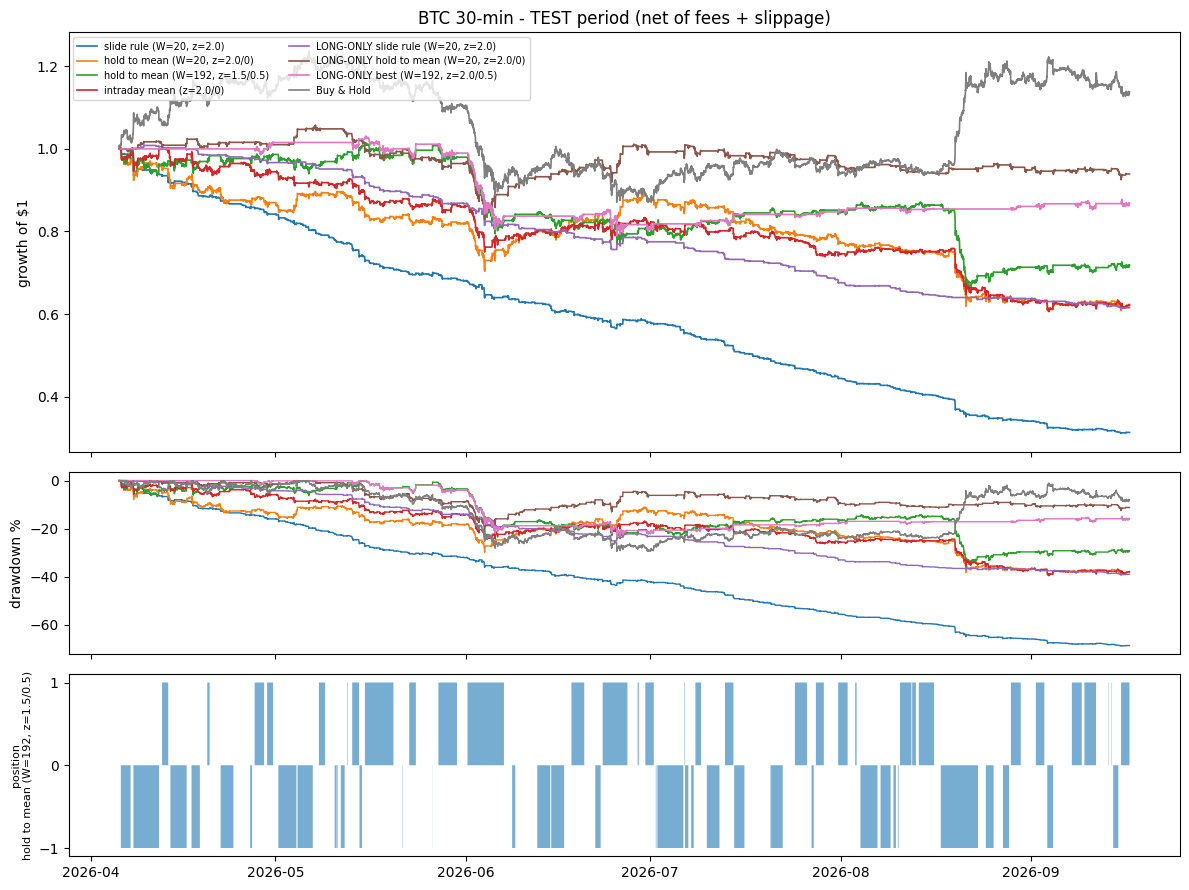

In [14]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True,
                         gridspec_kw={"height_ratios": [3, 1.3, 1.3]})
for name, res in test_results.items():
    axes[0].plot(res.equity.index, res.equity / res.equity.iloc[0], label=name, lw=1.2)
    axes[1].plot(res.equity.index, drawdown_series(res.equity) * 100, label=name, lw=1)
axes[0].set_ylabel("growth of $1")
axes[0].set_title("BTC 30-min - TEST period (net of fees + slippage)")
axes[0].legend(loc="upper left", fontsize=7, ncol=2)
axes[1].set_ylabel("drawdown %")
best_pos = test_results[BEST_NAME].positions["BTC"]
axes[2].fill_between(best_pos.index, best_pos, step="post", alpha=0.6)
axes[2].set_ylabel("position\n" + BEST_NAME, fontsize=8)
axes[2].set_yticks([-1, 0, 1])
plt.tight_layout()
fig.savefig(RESULTS_DIR / f"{TAG}_equity_drawdown.png", dpi=130)
plt.show()

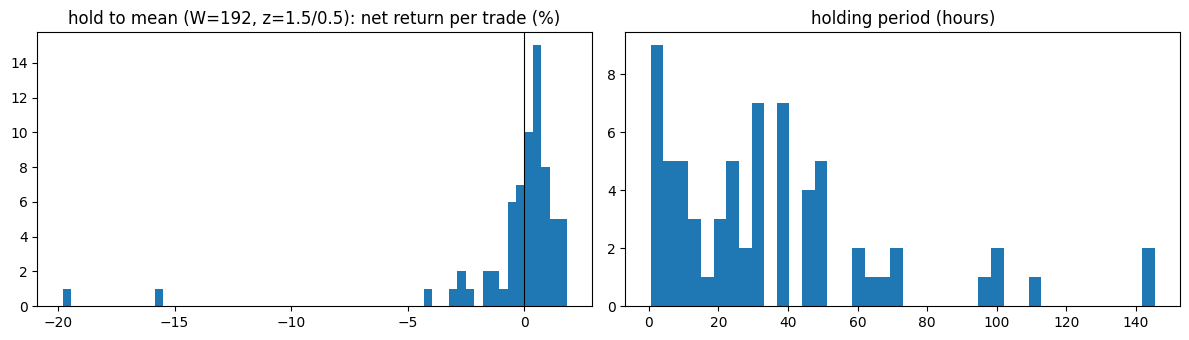

net_pnl                           return_pct                    
        count        mean           sum      count      mean       sum
side                                                                  
long       32 -399.568644 -12786.196613         32 -0.003810 -0.121936
short      36 -427.460165 -15388.565948         36 -0.004671 -0.168157

In [15]:
tr = test_results[BEST_NAME].trades
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(tr["return_pct"] * 100, bins=60)
axes[0].axvline(0, color="k", lw=0.8)
axes[0].set_title(f"{BEST_NAME}: net return per trade (%)")
axes[1].hist(tr["holding_period"].dt.total_seconds() / 3600, bins=40)
axes[1].set_title("holding period (hours)")
plt.tight_layout()
plt.show()
tr.groupby("side")[["net_pnl", "return_pct"]].agg(["count", "mean", "sum"])

## 9. Save outputs

In [16]:
table.to_csv(RESULTS_DIR / f"{TAG}_metrics_test.csv")
grid.to_csv(RESULTS_DIR / f"{TAG}_param_grid.csv", index=False)
test_results[BEST_NAME].trades.to_csv(RESULTS_DIR / f"{TAG}_trades_test.csv", index=False)
full_table.to_csv(RESULTS_DIR / f"{TAG}_metrics_by_period.csv")
print("saved to", RESULTS_DIR)
for f in sorted(RESULTS_DIR.glob(f"{TAG}_*")):
    print("  ", f.name)

saved to C:/Users/user/projects/Githubrepo/AlgoGoneCrazy-dev-model/model/results
   btc_mean_reversion_equity_drawdown.png
   btc_mean_reversion_metrics_by_period.csv
   btc_mean_reversion_metrics_test.csv
   btc_mean_reversion_param_grid.csv
   btc_mean_reversion_trades_test.csv


## Notes

- Costs: 10 bps fee + 2 bps slippage **per order**, so a round trip costs ~24 bps. Mean reversion on
  30-min bars trades often and targets small moves, so check *Annual Return (before costs)* vs
  *Annual Return* to see how much of the edge the costs eat.
- BTC trends strongly at times; a short at z > 2 in a rally can stay wrong for a long time.
  The LONG-ONLY columns show what is left when the short side is removed (and match what can
  actually be done on Binance spot without margin). Try `MAX_HOLD = 48` for a 1-day time stop.
- The grid is small on purpose (32 combinations per side) to limit overfitting to the validation window.